In [ ]:
# **How to use this notebook:**
# 1. Edit only the **Control Panel** cell below (`AVENUE`, `FOLD`, `SAMPLE_ROWS`, `K_CANDIDATES`).
# 2. Run top-to-bottom—each section checks `AVENUE` explicitly so prior runs never silently leak state.


from __future__ import annotations

import json
import os
from pathlib import Path
from typing import Any, Literal

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

In [2]:
# CONTROL PANEL (Edit here first)

AvenueType = Literal[
    "linear_nn_reg",
    "tree_gb_reg",
    "linear_nn_clf",
    "tree_gb_clf",
    "unsupervised",
]

AVENUE: AvenueType = "unsupervised"  # Change to inspect another avenue
FOLD: int = 1                        # 1..5 for supervised avenues
SAMPLE_ROWS: int = 100_000           # Cap for heavy pairwise/clustering/plot ops
K_CANDIDATES: list[int] = [2, 3, 4, 5, 6]
RANDOM_STATE: int = 42
SAVE_FIGURES: bool = False

cwd = Path(os.getcwd())
parent = cwd.parent if cwd.name.lower() == "notebooks" else cwd
data_dir = parent / "Data" / "preprocessed_eda"
fig_dir = parent / "images" / "eda_04"
if SAVE_FIGURES:
    fig_dir.mkdir(parents=True, exist_ok=True)

print(f"Selected AVENUE : {AVENUE} | FOLD: {FOLD} | SAMPLE_ROWS: {SAMPLE_ROWS:,}")
print(f"Artifacts dir   : {data_dir}")

Selected AVENUE : unsupervised | FOLD: 1 | SAMPLE_ROWS: 100,000
Artifacts dir   : c:\Users\Marty\Documents\School\Merrimack College\8) DSE6311 Data Science Capstone\team_omega\Data\preprocessed_eda


In [3]:
# ## 1. Canonical Artifact Loader (Avenue-Aware)

def load_manifest(eda_dir: Path) -> dict[str, Any]:
    manifest_path = eda_dir / "manifest.json"
    if not manifest_path.exists():
        raise FileNotFoundError(f"Missing manifest.json at {manifest_path}")
    return json.loads(manifest_path.read_text(encoding="utf-8"))


def load_avenue_bundle(
    avenue: AvenueType,
    eda_dir: Path,
    fold: int = 1,
) -> dict[str, Any]:
    """Load canonical artifacts for a single avenue without mutating global state."""
    manifest = load_manifest(eda_dir)

    if avenue == "unsupervised":
        unsup_path = eda_dir / "unsupervised_transformed.parquet"
        df_unsup = pl.read_parquet(unsup_path)
        return {
            "avenue": avenue,
            "is_unsupervised": True,
            "is_classification": False,
            "requires_infold_transform": True,
            "target_col": None,
            "df_unsupervised": df_unsup,
            "manifest": manifest,
        }

    if not (1 <= fold <= int(manifest.get("n_splits", 5))):
        raise ValueError(f"`fold` must be between 1 and {manifest.get('n_splits', 5)}, got {fold}.")

    df_train_raw = pl.read_parquet(eda_dir / "train_raw_80.parquet")
    df_test_raw = pl.read_parquet(eda_dir / "test_raw_20.parquet")
    meta_train = pl.read_parquet(eda_dir / "removed_cols_train.parquet")
    kfold_npz = np.load(eda_dir / "group_kfold_5_indices.npz")

    tr_idx = kfold_npz[f"fold_{fold}_tr_idx"]
    val_idx = kfold_npz[f"fold_{fold}_val_idx"]

    is_clf = avenue.endswith("_clf")
    requires_transform = avenue.startswith("linear_nn_")
    target_col = manifest["target_clf"] if is_clf else manifest["target_reg"]

    # Join removed metadata (ID, From, Date, targets, etc.) on _row_id when present
    if "_row_id" in df_train_raw.columns and "_row_id" in meta_train.columns:
        df_train_full = df_train_raw.join(meta_train, on="_row_id", how="left", suffix="_meta")
        # Prefer target column if duplicated across train_raw and meta
        if f"{target_col}_meta" in df_train_full.columns and target_col not in df_train_full.columns:
            df_train_full = df_train_full.rename({f"{target_col}_meta": target_col})
    else:
        df_train_full = df_train_raw

    return {
        "avenue": avenue,
        "fold": fold,
        "is_unsupervised": False,
        "is_classification": is_clf,
        "requires_infold_transform": requires_transform,
        "target_col": target_col,
        "df_train_full": df_train_full,
        "df_test_raw": df_test_raw,
        "tr_idx": tr_idx,
        "val_idx": val_idx,
        "kfold_npz": kfold_npz,
        "manifest": manifest,
    }


bundle = load_avenue_bundle(AVENUE, data_dir, fold=FOLD)
manifest = bundle["manifest"]
print("Loaded bundle keys:", list(bundle.keys()))

Loaded bundle keys: ['avenue', 'is_unsupervised', 'is_classification', 'requires_infold_transform', 'target_col', 'df_unsupervised', 'manifest']


In [4]:
# ## 2. Fold-to-Fold Household (`ID`) & Target Diagnostics (Supervised Avenues)

def inspect_fold_balance(bundle: dict[str, Any]) -> pl.DataFrame:
    """Check household counts, row counts, and target summaries across all folds."""
    if bundle["is_unsupervised"]:
        print("Skipping fold balance: AVENUE == 'unsupervised' (100% dataset, no k-fold split).")
        return pl.DataFrame()

    df_train = bundle["df_train_full"]
    target_col = bundle["target_col"]
    n_splits = int(bundle["manifest"].get("n_splits", 5))
    npz = bundle["kfold_npz"]

    rows: list[dict[str, Any]] = []
    for k in range(1, n_splits + 1):
        tr_i = npz[f"fold_{k}_tr_idx"].tolist()
        va_i = npz[f"fold_{k}_val_idx"].tolist()

        tr_slice = df_train[tr_i]
        va_slice = df_train[va_i]

        tr_hh = set(tr_slice["ID"].to_list()) if "ID" in tr_slice.columns else set()
        va_hh = set(va_slice["ID"].to_list()) if "ID" in va_slice.columns else set()
        overlap_hh = len(tr_hh & va_hh)

        rec: dict[str, Any] = {
            "fold": k,
            "n_train_rows": tr_slice.height,
            "n_val_rows": va_slice.height,
            "n_train_households": len(tr_hh),
            "n_val_households": len(va_hh),
            "leak_overlap_households": overlap_hh,
        }

        if target_col and target_col in va_slice.columns:
            y_va = va_slice[target_col].drop_nulls()
            rec["val_target_mean"] = float(y_va.mean()) if y_va.len() > 0 else np.nan
            rec["val_target_median"] = float(y_va.median()) if y_va.len() > 0 else np.nan
            if bundle["is_classification"]:
                rec["val_pos_rate"] = float(y_va.mean()) if y_va.len() > 0 else np.nan

        rows.append(rec)

    summary = pl.DataFrame(rows)
    print(summary)
    return summary


fold_summary_df = inspect_fold_balance(bundle)

Skipping fold balance: AVENUE == 'unsupervised' (100% dataset, no k-fold split).


In [5]:
# ## 3. Feature Correlations & Tail / Outlier Sensitivity

def inspect_numeric_correlations(
    df: pl.DataFrame,
    sample_rows: int = 100_000,
    seed: int = 42,
    top_pairs: int = 12,
) -> None:
    """Compute sample Pearson correlations among numeric features to flag collinearity."""
    num_cols = [
        c for c, dt in df.schema.items()
        if c != "_row_id" and dt in (
            pl.Int8, pl.Int16, pl.Int32, pl.Int64,
            pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64,
            pl.Float32, pl.Float64,
        )
    ]
    if len(num_cols) < 2:
        print("Fewer than 2 numeric columns available for correlation check.")
        return

    n_take = min(sample_rows, df.height)
    sub_pd = df.sample(n=n_take, seed=seed).select(num_cols).to_pandas()
    corr = sub_pd.corr(method="pearson")

    # Extract highest-magnitude off-diagonal pairs
    pairs: list[tuple[str, str, float]] = []
    cols_arr = corr.columns.to_list()
    for i in range(len(cols_arr)):
        for j in range(i + 1, len(cols_arr)):
            val = float(corr.iloc[i, j])
            if not np.isnan(val):
                pairs.append((cols_arr[i], cols_arr[j], val))

    pairs.sort(key=lambda t: abs(t[2]), reverse=True)
    print(f"Top {min(top_pairs, len(pairs))} |r| pairs (sample n={n_take:,}):")
    for a, b, r in pairs[:top_pairs]:
        print(f"  {a:<26} <-> {b:<26} : r = {r:+.4f}")


if bundle["is_unsupervised"]:
    inspect_numeric_correlations(bundle["df_unsupervised"], sample_rows=SAMPLE_ROWS, seed=RANDOM_STATE)
else:
    inspect_numeric_correlations(bundle["df_train_full"], sample_rows=SAMPLE_ROWS, seed=RANDOM_STATE)

Top 12 |r| pairs (sample n=100,000):
  num__ghi_Wh_m2             <-> num__photons_m2            : r = +1.0000
  cat__Price_profile_C       <-> cat__Price_level_5_10      : r = +1.0000
  cat__Municipality_Bodø     <-> cat__Group_Phase2_Bo_1     : r = +1.0000
  cat__Municipality_Trondheim <-> cat__Group_Phase2_Trond_1  : r = +1.0000
  cat__Which_Phases_Participate_Both <-> cat__Which_Phases_Participate_Phase_2 : r = -1.0000
  num__ghi_Wh_m2             <-> num__par_photons_m2        : r = +1.0000
  num__photons_m2            <-> num__par_photons_m2        : r = +1.0000
  num__photons_m2            <-> num__par_mol_m2            : r = +1.0000
  num__ghi_Wh_m2             <-> num__par_mol_m2            : r = +1.0000
  num__par_photons_m2        <-> num__par_mol_m2            : r = +1.0000
  num__Temperature48         <-> num__Temperature72         : r = +0.9800
  num__Temperature24         <-> num__Temperature48         : r = +0.9662


In [6]:
def inspect_fpi_tail_sensitivity(bundle: dict[str, Any]) -> None:
    """Inspect FPI tail bands and High_Flexibility_Flag balance when target is present."""
    if bundle["is_unsupervised"]:
        print("Skipping FPI target tail check: AVENUE == 'unsupervised'.")
        return

    df_train = bundle["df_train_full"]
    fpi_col = bundle["manifest"].get("target_reg", "Flexibility_Performance_Index")
    clf_col = bundle["manifest"].get("target_clf", "High_Flexibility_Flag")

    if fpi_col in df_train.columns:
        s = df_train[fpi_col].drop_nulls()
        q = s.quantile
        tail_stats = pl.DataFrame([{
            "n": s.len(),
            "min": float(s.min()),
            "p01": float(s.quantile(0.01)),
            "p05": float(s.quantile(0.05)),
            "median": float(s.median()),
            "p95": float(s.quantile(0.95)),
            "p99": float(s.quantile(0.99)),
            "max": float(s.max()),
            "pct_below_neg5": float((s < -5.0).mean() * 100.0),
            "pct_neg5_to_neg1": float(((s >= -5.0) & (s <= -1.0)).mean() * 100.0),
            "pct_above_pos1": float((s > 1.0).mean() * 100.0),
        }])
        print("FPI distribution & tail quantiles (train_raw_80):")
        print(tail_stats)

    if clf_col in df_train.columns:
        c_s = df_train[clf_col].drop_nulls()
        print(f"{clf_col} positive rate (train_raw_80): {float(c_s.mean()):.4f} (n={c_s.len():,})")


inspect_fpi_tail_sensitivity(bundle)

Skipping FPI target tail check: AVENUE == 'unsupervised'.


Unsupervised feature breakdown: total=50 | numeric/other=13 | OHE (cat__*)=37
Sample variance share -> non-cat cols: 92.5% | cat__* OHE cols: 7.5%
PCA explained variance ratio (PC1, PC2): [0.8317 0.0407]


c:\Users\Marty\anaconda3\envs\capstone_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)



K-Means diagnostic sweep:
shape: (5, 4)
┌─────┬───────────────┬────────────────┬────────────────────┐
│ k   ┆ inertia       ┆ silhouette_25k ┆ seed_ari_stability │
│ --- ┆ ---           ┆ ---            ┆ ---                │
│ i64 ┆ f64           ┆ f64            ┆ f64                │
╞═════╪═══════════════╪════════════════╪════════════════════╡
│ 2   ┆ 1.6087e6      ┆ 0.68367        ┆ 1.0                │
│ 3   ┆ 1.0885e6      ┆ 0.558607       ┆ 1.0                │
│ 4   ┆ 910992.629564 ┆ 0.434811       ┆ 0.999405           │
│ 5   ┆ 809868.977553 ┆ 0.208388       ┆ 0.997838           │
│ 6   ┆ 746377.236414 ┆ 0.215778       ┆ 0.762101           │
└─────┴───────────────┴────────────────┴────────────────────┘


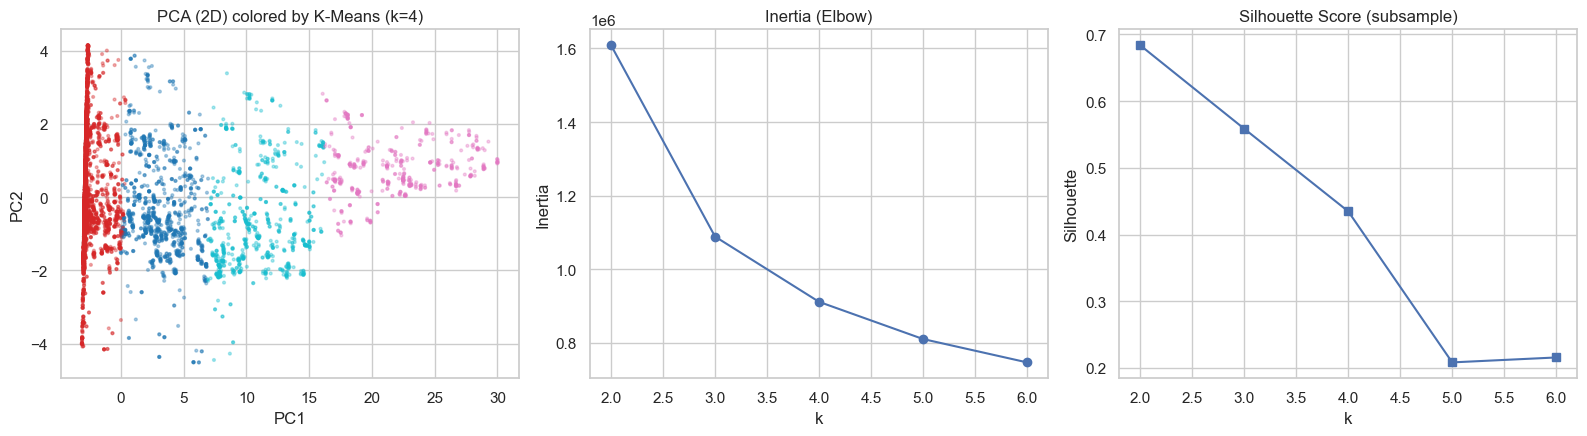

In [7]:
# ## 4. Unsupervised K-Means Diagnostics (Feature Dominance, Tendency & $k$ Selection)
# Runs when `AVENUE == "unsupervised"`. Evaluates:
# - **Column group share**: scaled numeric features vs. one-hot encoded (`cat__*`) indicator columns.
# - **2D PCA structure** & **K-Means inertia / silhouette / seed stability** on a stratified/random sample.

def run_kmeans_diagnostics(
    df_unsup: pl.DataFrame,
    k_candidates: list[int] = [2, 3, 4, 5, 6],
    sample_rows: int = 100_000,
    seed: int = 42,
    save_figs: bool = False,
    out_figs_dir: Path | None = None,
) -> dict[str, Any]:
    feature_cols = [c for c in df_unsup.columns if c != "_row_id"]
    ohe_like_cols = [c for c in feature_cols if c.startswith("cat__")]
    num_like_cols = [c for c in feature_cols if not c.startswith("cat__")]

    print(
        f"Unsupervised feature breakdown: total={len(feature_cols)} | "
        f"numeric/other={len(num_like_cols)} | OHE (cat__*)={len(ohe_like_cols)}"
    )

    n_take = min(sample_rows, df_unsup.height)
    X_sample = (
        df_unsup.sample(n=n_take, seed=seed)
        .select(feature_cols)
        .to_numpy()
    )
    X_sample = np.nan_to_num(X_sample, nan=0.0, posinf=0.0, neginf=0.0)

    # Check per-column variance contribution (proxy for Euclidean distance dominance)
    col_vars = np.var(X_sample, axis=0)
    total_var = float(np.sum(col_vars)) if float(np.sum(col_vars)) > 0 else 1.0
    num_var_share = float(np.sum(col_vars[: len(num_like_cols)])) / total_var
    ohe_var_share = float(np.sum(col_vars[len(num_like_cols) :])) / total_var
    print(
        f"Sample variance share -> non-cat cols: {num_var_share:.1%} | "
        f"cat__* OHE cols: {ohe_var_share:.1%}"
    )

    # PCA 2D projection for quick visual inspection
    pca = PCA(n_components=2, random_state=seed)
    X_pca = pca.fit_transform(X_sample)
    print(f"PCA explained variance ratio (PC1, PC2): {pca.explained_variance_ratio_.round(4)}")

    # K-Means sweep across k_candidates (use silhouette on a subset if n_take > 25_000 for speed)
    sil_sample_n = min(25_000, X_sample.shape[0])
    rng = np.random.default_rng(seed)
    sil_idx = rng.choice(X_sample.shape[0], size=sil_sample_n, replace=False)

    sweep_rows: list[dict[str, Any]] = []
    labels_by_k: dict[int, np.ndarray] = {}

    for k in k_candidates:
        km_a = KMeans(n_clusters=k, n_init=10, random_state=seed)
        lbl_a = km_a.fit_predict(X_sample)
        labels_by_k[k] = lbl_a

        km_b = KMeans(n_clusters=k, n_init=10, random_state=seed + 100)
        lbl_b = km_b.fit_predict(X_sample)

        sil_score = float(silhouette_score(X_sample[sil_idx], lbl_a[sil_idx]))
        ari_stability = float(adjusted_rand_score(lbl_a, lbl_b))

        sweep_rows.append({
            "k": k,
            "inertia": float(km_a.inertia_),
            "silhouette_25k": sil_score,
            "seed_ari_stability": ari_stability,
        })

    sweep_df = pl.DataFrame(sweep_rows)
    print("\nK-Means diagnostic sweep:")
    print(sweep_df)

    # Plot PCA colored by first k candidate + Elbow/Silhouette side-by-side
    k_show = k_candidates[len(k_candidates) // 2] if k_candidates else 3
    lbl_show = labels_by_k[k_show]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].scatter(X_pca[:10_000, 0], X_pca[:10_000, 1], c=lbl_show[:10_000], s=4, alpha=0.35, cmap="tab10")
    axes[0].set_title(f"PCA (2D) colored by K-Means (k={k_show})")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")

    ks = sweep_df["k"].to_list()
    inertias = sweep_df["inertia"].to_list()
    sils = sweep_df["silhouette_25k"].to_list()

    axes[1].plot(ks, inertias, marker="o")
    axes[1].set_title("Inertia (Elbow)")
    axes[1].set_xlabel("k")
    axes[1].set_ylabel("Inertia")

    axes[2].plot(ks, sils, marker="s")
    axes[2].set_title("Silhouette Score (subsample)")
    axes[2].set_xlabel("k")
    axes[2].set_ylabel("Silhouette")

    plt.tight_layout()
    if save_figs and out_figs_dir is not None:
        fig.savefig(out_figs_dir / f"kmeans_diagnostics_sample_{n_take}.png", dpi=150)
    plt.show()

    return {
        "sweep_df": sweep_df,
        "pca": pca,
        "num_var_share": num_var_share,
        "ohe_var_share": ohe_var_share,
    }


if bundle["is_unsupervised"]:
    kmeans_results = run_kmeans_diagnostics(
        bundle["df_unsupervised"],
        k_candidates=K_CANDIDATES,
        sample_rows=SAMPLE_ROWS,
        seed=RANDOM_STATE,
        save_figs=SAVE_FIGURES,
        out_figs_dir=fig_dir,
    )
else:
    print(
        f"AVENUE is '{AVENUE}'. Switch AVENUE = 'unsupervised' in the Control Panel "
        "above to run K-Means clustering diagnostics."
    )